# Distance Sweep — T1 Mortality vs CCP-R1 Distance

Sliced from full factorial grid: bcas=0.07, inter_bn=70.
Paired seed comparison: stovepipe vs ambulance pooling.

In [49]:
import sys
from pathlib import Path
_root = Path(".").resolve()
while not (_root / "paths.py").exists():
    _root = _root.parent
sys.path.insert(0, str(_root))

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

df = pd.read_csv(_root / "data_cluster/fullgrid/results.csv")
print(f"Loaded {len(df)} runs")

# Filter: bcas=0.07, inter_bn=70
mask = (df["bcas_rate"] == 0.07) & (df["ccp_r1_inter_bn_min"] == 70)
stove = df[mask & (df["facility_eligibility"] == 0) & (df["ambulance_eligibility"] == 0)].copy()
amb   = df[mask & (df["facility_eligibility"] == 0) & (df["ambulance_eligibility"] == 1)].copy()

distances = sorted(stove["ccp_r1_same_bn_min"].unique())
print(f"Stovepipe: {len(stove)}, Amb pooling: {len(amb)}")
print(f"Distances: {distances}")
print(f"Seeds per distance: {stove.groupby('ccp_r1_same_bn_min').size().unique()}")

Loaded 405600 runs
Stovepipe: 1300, Amb pooling: 1300
Distances: [np.int64(10), np.int64(15), np.int64(20), np.int64(25), np.int64(30), np.int64(35), np.int64(40), np.int64(45), np.int64(50), np.int64(55), np.int64(60), np.int64(65), np.int64(70)]
Seeds per distance: [100]


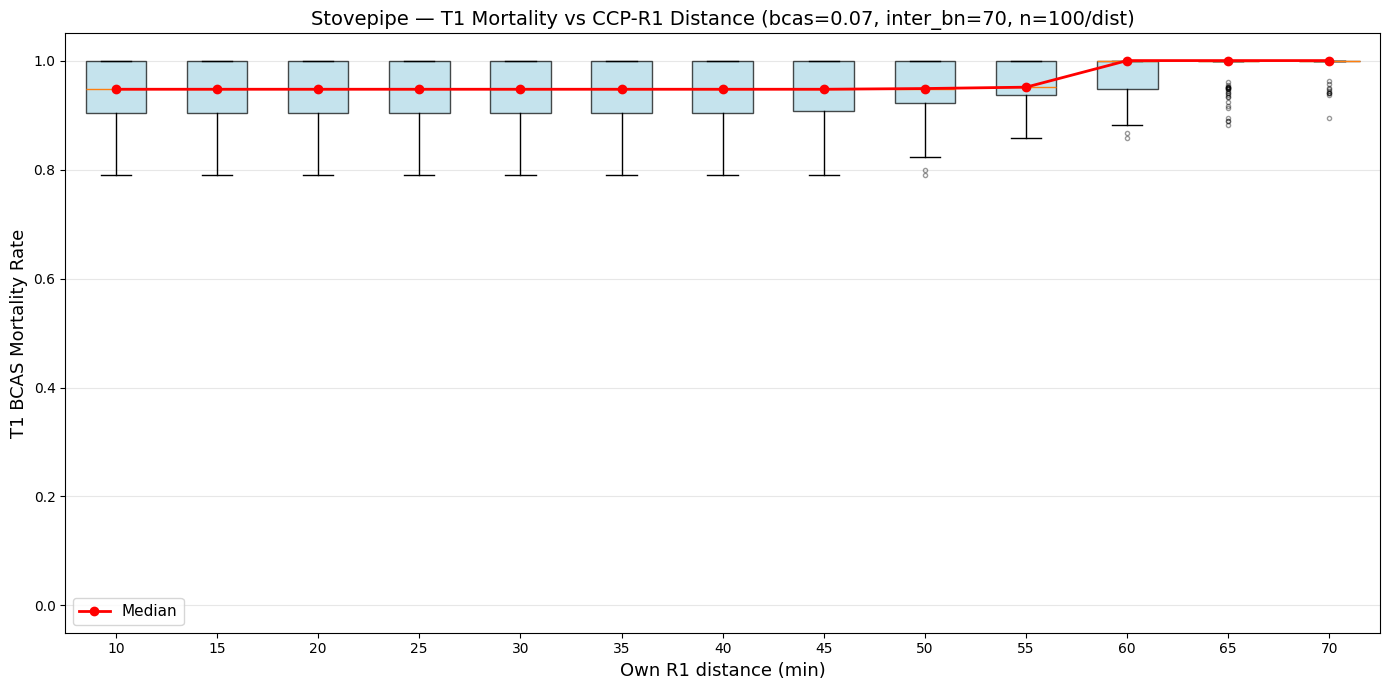

Median mortality per distance:
   10 min: 0.947
   15 min: 0.947
   20 min: 0.947
   25 min: 0.947
   30 min: 0.947
   35 min: 0.947
   40 min: 0.947
   45 min: 0.947
   50 min: 0.949
   55 min: 0.951
   60 min: 1.000
   65 min: 1.000
   70 min: 1.000


In [50]:
# T1 mortality vs own R1 distance — boxplot + median line (stovepipe)
mortality_by_dist = [stove[stove["ccp_r1_same_bn_min"] == d]["death_rate_T1_BCAS"].values for d in distances]
medians = [np.median(m) for m in mortality_by_dist]

fig, ax = plt.subplots(figsize=(14, 7))
bp = ax.boxplot(mortality_by_dist, positions=range(len(distances)), widths=0.6,
                patch_artist=True, showfliers=True, flierprops=dict(markersize=3, alpha=0.4))
for patch in bp["boxes"]:
    patch.set_facecolor("lightblue")
    patch.set_alpha(0.7)

ax.plot(range(len(distances)), medians, "ro-", linewidth=2, markersize=6, label="Median", zorder=5)

ax.set_xticks(range(len(distances)))
ax.set_xticklabels(distances)
ax.set_xlabel("Own R1 distance (min)", fontsize=13)
ax.set_ylabel("T1 BCAS Mortality Rate", fontsize=13)
ax.set_title("Stovepipe — T1 Mortality vs CCP-R1 Distance (bcas=0.07, inter_bn=70, n=100/dist)", fontsize=14)
ax.legend(fontsize=11)
ax.grid(True, alpha=0.3, axis="y")
ax.set_ylim(-0.05, 1.05)
plt.tight_layout()
plt.show()

print("Median mortality per distance:")
for d, m in zip(distances, medians):
    print(f"  {d:3d} min: {m:.3f}")

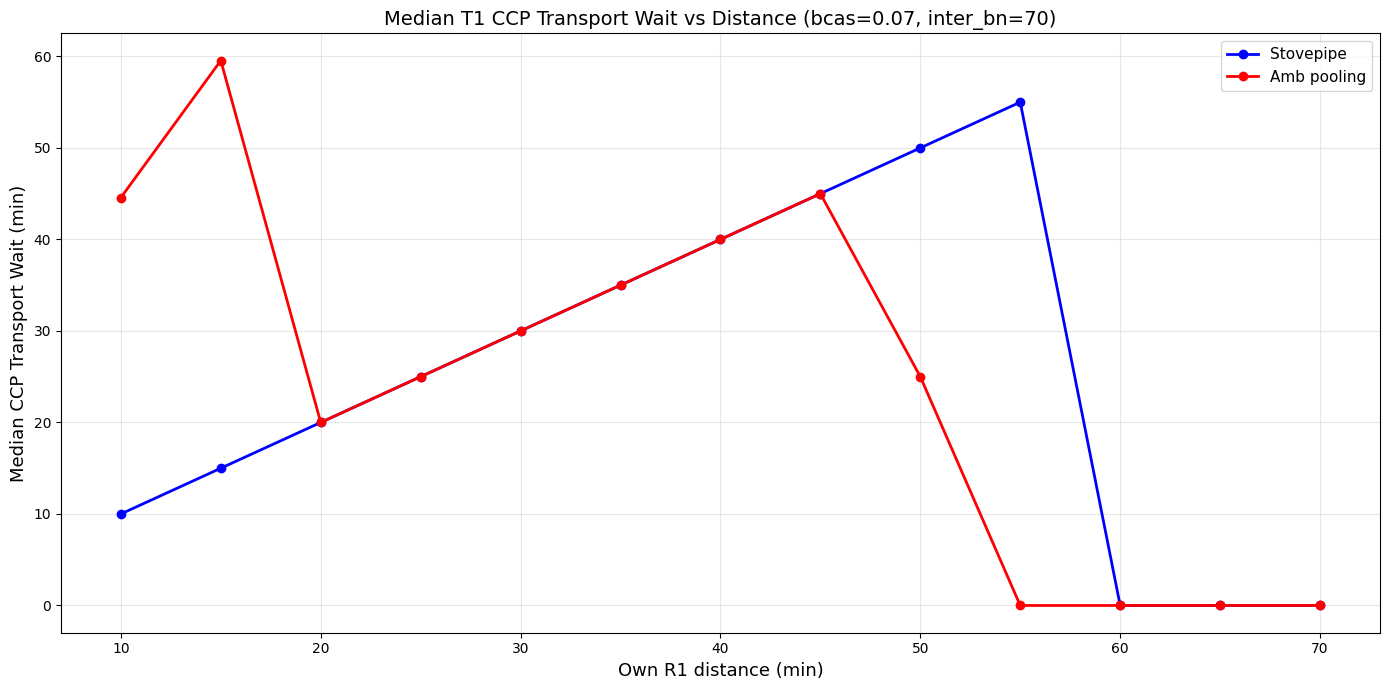

In [51]:
# Median CCP transport wait time vs distance
wait_stove = stove.groupby("ccp_r1_same_bn_min")["median_wait_ccp_transport_T1"].median()
wait_amb   = amb.groupby("ccp_r1_same_bn_min")["median_wait_ccp_transport_T1"].median()

fig, ax = plt.subplots(figsize=(14, 7))
ax.plot(wait_stove.index, wait_stove.values, "bo-", linewidth=2, markersize=6, label="Stovepipe")
ax.plot(wait_amb.index, wait_amb.values, "ro-", linewidth=2, markersize=6, label="Amb pooling")
ax.set_xlabel("Own R1 distance (min)", fontsize=13)
ax.set_ylabel("Median CCP Transport Wait (min)", fontsize=13)
ax.set_title("Median T1 CCP Transport Wait vs Distance (bcas=0.07, inter_bn=70)", fontsize=14)
ax.legend(fontsize=11)
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

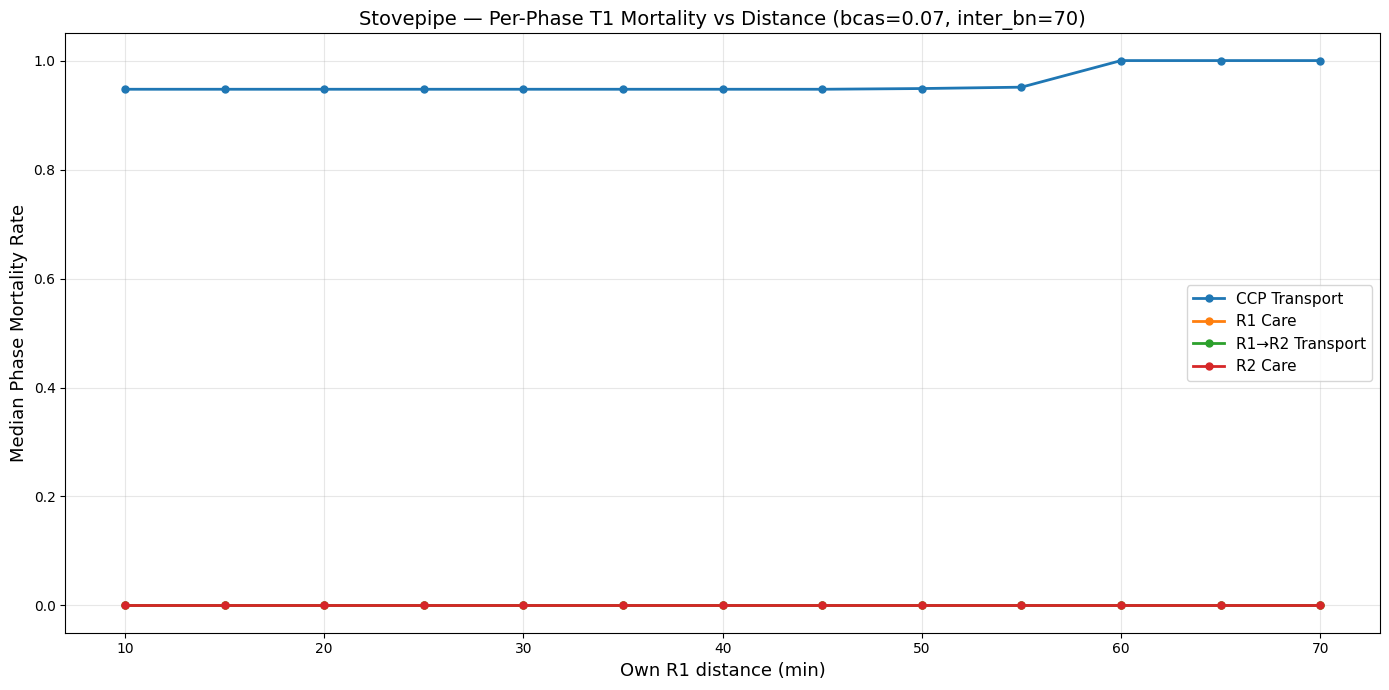

In [52]:
# Per-phase mortality breakdown vs distance (stovepipe)
phases = ["mortality_ccp_transport_T1", "mortality_r1_care_T1", "mortality_r1_transport_T1", "mortality_r2_care_T1"]
labels = ["CCP Transport", "R1 Care", "R1→R2 Transport", "R2 Care"]

fig, ax = plt.subplots(figsize=(14, 7))
for phase, label in zip(phases, labels):
    med = stove.groupby("ccp_r1_same_bn_min")[phase].median()
    ax.plot(med.index, med.values, "o-", linewidth=2, markersize=5, label=label)

ax.set_xlabel("Own R1 distance (min)", fontsize=13)
ax.set_ylabel("Median Phase Mortality Rate", fontsize=13)
ax.set_title("Stovepipe — Per-Phase T1 Mortality vs Distance (bcas=0.07, inter_bn=70)", fontsize=14)
ax.legend(fontsize=11)
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

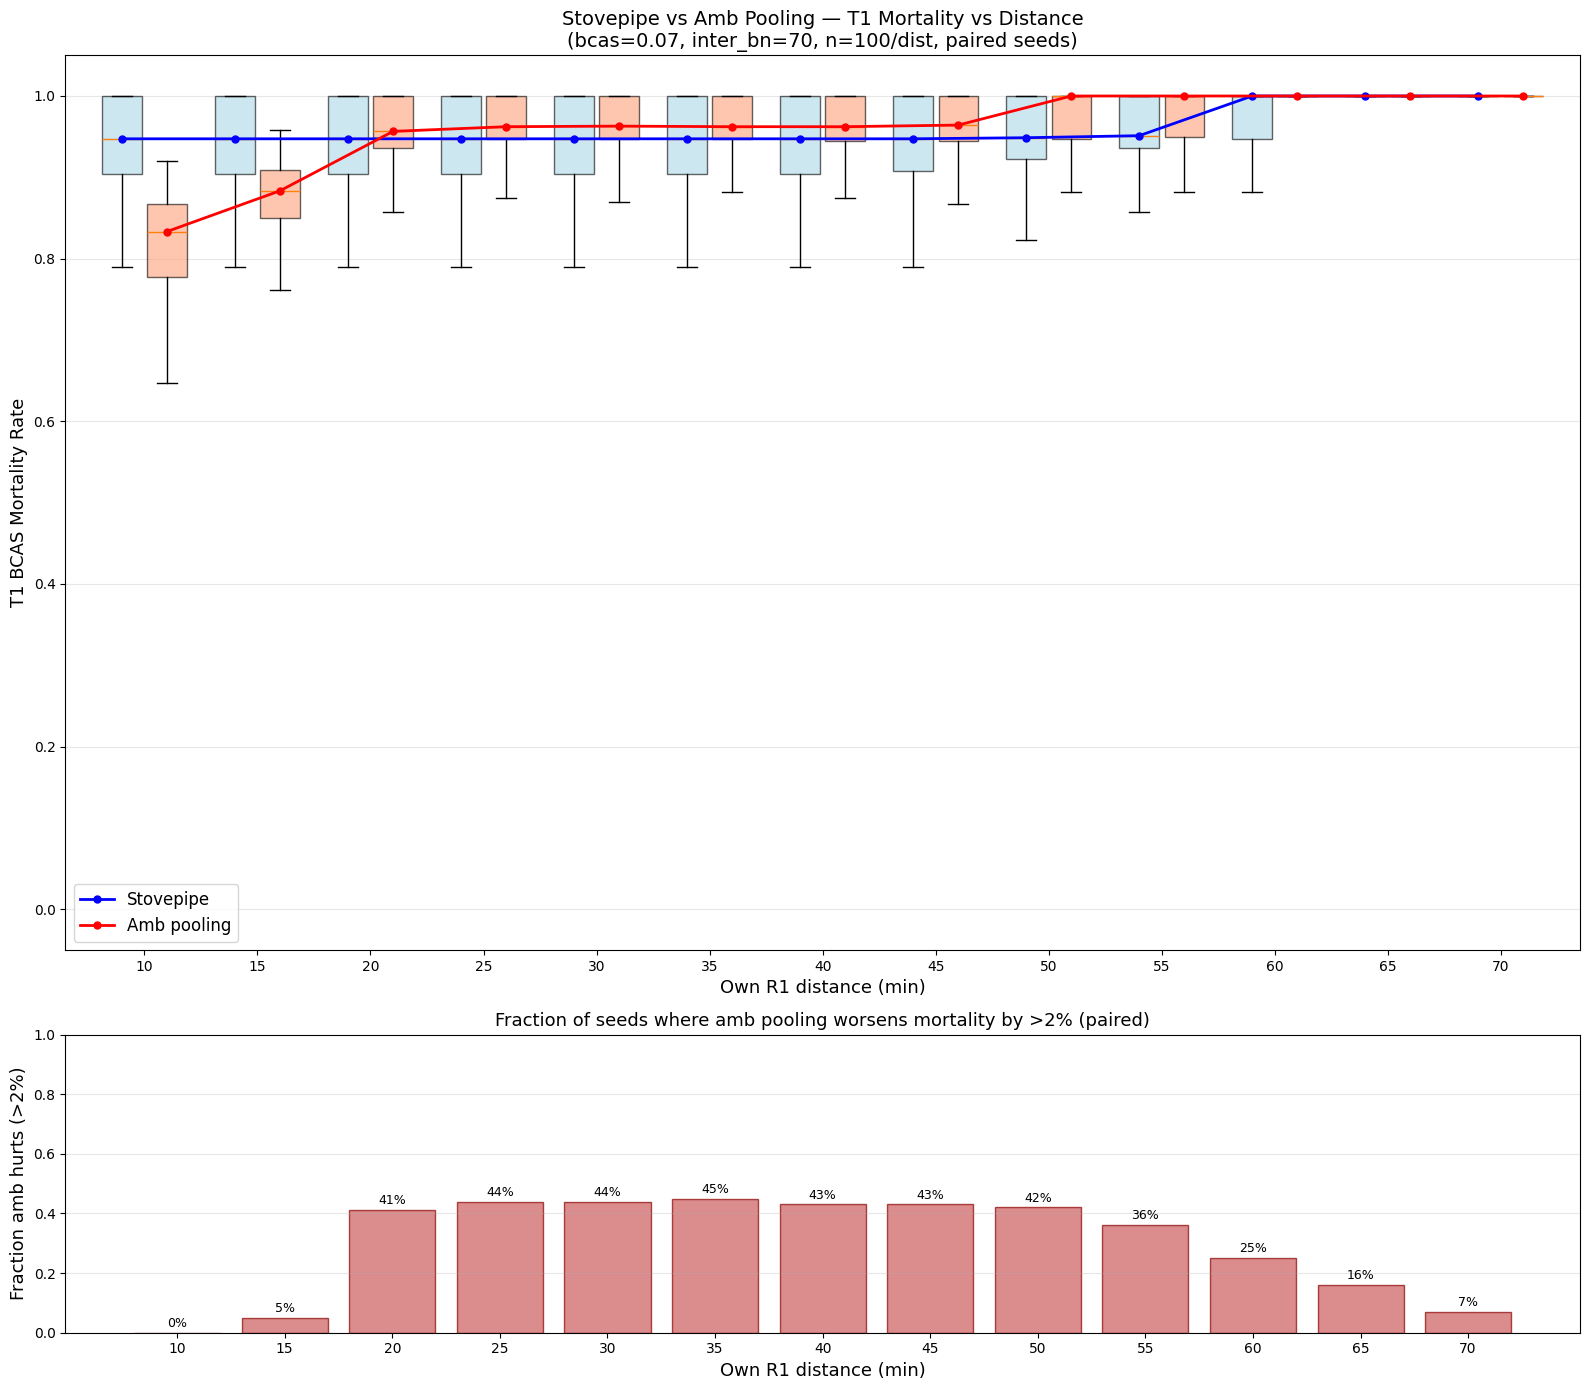


Median mortality comparison:
 Dist    Stove      Amb    Delta   %Hurt
   10    0.947    0.833   +0.114     0%
   15    0.947    0.883   +0.064     5%
   20    0.947    0.957   -0.009    41%
   25    0.947    0.962   -0.015    44%
   30    0.947    0.963   -0.016    44%
   35    0.947    0.962   -0.015    45%
   40    0.947    0.962   -0.015    43%
   45    0.947    0.964   -0.017    43%
   50    0.949    1.000   -0.051    42%
   55    0.951    1.000   -0.049    36%
   60    1.000    1.000   +0.000    25%
   65    1.000    1.000   +0.000    16%
   70    1.000    1.000   +0.000     7%


In [53]:
# Overlay: stove vs amb pooling — paired by seed from full grid
mort_stove = [stove[stove["ccp_r1_same_bn_min"] == d]["death_rate_T1_BCAS"].values for d in distances]
mort_amb   = [amb[amb["ccp_r1_same_bn_min"] == d]["death_rate_T1_BCAS"].values for d in distances]
med_stove  = [np.median(m) for m in mort_stove]
med_amb    = [np.median(m) for m in mort_amb]

fig, axes = plt.subplots(2, 1, figsize=(16, 14), gridspec_kw={"height_ratios": [3, 1]})

# ── Top: side-by-side boxplots ──
ax = axes[0]
bp1 = ax.boxplot(mort_stove, positions=np.arange(len(distances)) - 0.2, widths=0.35,
                 patch_artist=True, showfliers=False)
for patch in bp1["boxes"]:
    patch.set_facecolor("lightblue"); patch.set_alpha(0.6)

bp2 = ax.boxplot(mort_amb, positions=np.arange(len(distances)) + 0.2, widths=0.35,
                 patch_artist=True, showfliers=False)
for patch in bp2["boxes"]:
    patch.set_facecolor("lightsalmon"); patch.set_alpha(0.6)

ax.plot(np.arange(len(distances)) - 0.2, med_stove, "bo-", linewidth=2, markersize=5, label="Stovepipe", zorder=5)
ax.plot(np.arange(len(distances)) + 0.2, med_amb, "ro-", linewidth=2, markersize=5, label="Amb pooling", zorder=5)

ax.set_xticks(range(len(distances)))
ax.set_xticklabels(distances)
ax.set_xlabel("Own R1 distance (min)", fontsize=13)
ax.set_ylabel("T1 BCAS Mortality Rate", fontsize=13)
ax.set_title("Stovepipe vs Amb Pooling — T1 Mortality vs Distance\n(bcas=0.07, inter_bn=70, n=100/dist, paired seeds)", fontsize=14)
ax.legend(fontsize=12)
ax.grid(True, alpha=0.3, axis="y")
ax.set_ylim(-0.05, 1.05)

# ── Bottom: fraction of seeds where amb hurts (paired) ──
ax2 = axes[1]
frac_hurt = []
for d in distances:
    s = stove[stove["ccp_r1_same_bn_min"] == d].set_index("seed")["death_rate_T1_BCAS"]
    a = amb[amb["ccp_r1_same_bn_min"] == d].set_index("seed")["death_rate_T1_BCAS"]
    paired = s.align(a, join="inner")
    delta = paired[1] - paired[0]  # amb - stove: positive = amb worse
    frac_hurt.append((delta > 0.02).mean())

ax2.bar(range(len(distances)), frac_hurt, color="indianred", alpha=0.7, edgecolor="darkred")
ax2.set_xticks(range(len(distances)))
ax2.set_xticklabels(distances)
ax2.set_xlabel("Own R1 distance (min)", fontsize=13)
ax2.set_ylabel("Fraction amb hurts (>2%)", fontsize=13)
ax2.set_title("Fraction of seeds where amb pooling worsens mortality by >2% (paired)", fontsize=13)
ax2.grid(True, alpha=0.3, axis="y")
ax2.set_ylim(0, 1)
for i, f in enumerate(frac_hurt):
    ax2.text(i, f + 0.02, f"{f:.0%}", ha="center", fontsize=9)

plt.tight_layout()
plt.show()

print("\nMedian mortality comparison:")
print(f"{'Dist':>5s}  {'Stove':>7s}  {'Amb':>7s}  {'Delta':>7s}  {'%Hurt':>6s}")
for d, ms, ma, fh in zip(distances, med_stove, med_amb, frac_hurt):
    print(f"{d:5d}  {ms:7.3f}  {ma:7.3f}  {ms - ma:+7.3f}  {fh:5.0%}")

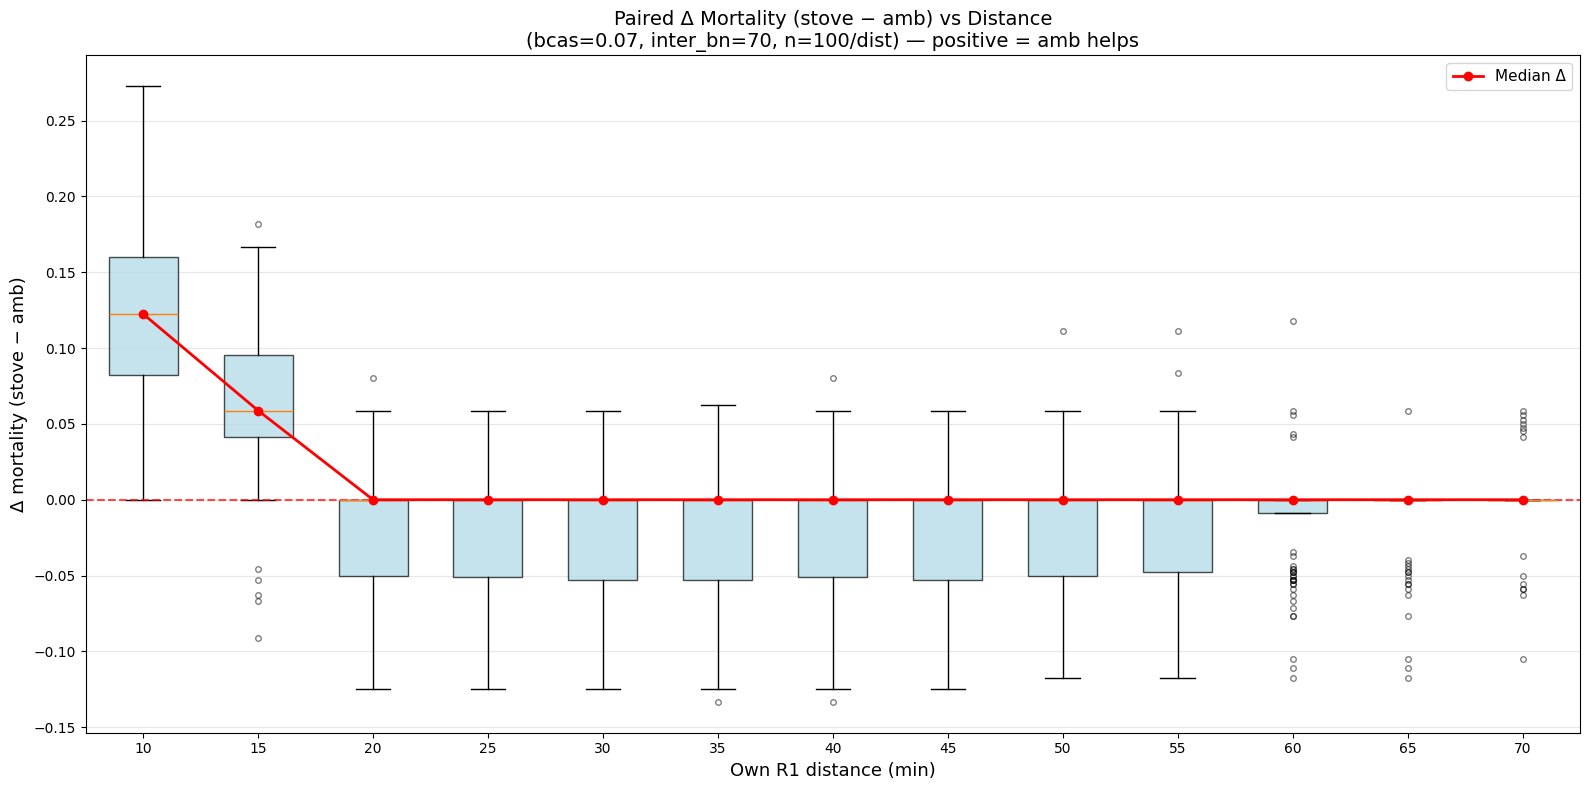

Median Δ per distance:
   10 min: median Δ=+0.1225, amb hurts >2pp in 0%
   15 min: median Δ=+0.0588, amb hurts >2pp in 5%
   20 min: median Δ=+0.0000, amb hurts >2pp in 41%
   25 min: median Δ=+0.0000, amb hurts >2pp in 44%
   30 min: median Δ=+0.0000, amb hurts >2pp in 44%
   35 min: median Δ=+0.0000, amb hurts >2pp in 45%
   40 min: median Δ=+0.0000, amb hurts >2pp in 43%
   45 min: median Δ=+0.0000, amb hurts >2pp in 43%
   50 min: median Δ=+0.0000, amb hurts >2pp in 42%
   55 min: median Δ=+0.0000, amb hurts >2pp in 36%
   60 min: median Δ=+0.0000, amb hurts >2pp in 25%
   65 min: median Δ=+0.0000, amb hurts >2pp in 16%
   70 min: median Δ=+0.0000, amb hurts >2pp in 7%


In [54]:
# Paired delta (stove - amb) boxplot per distance
deltas_by_dist = []
for d in distances:
    s = stove[stove["ccp_r1_same_bn_min"] == d].set_index("seed")["death_rate_T1_BCAS"]
    a = amb[amb["ccp_r1_same_bn_min"] == d].set_index("seed")["death_rate_T1_BCAS"]
    paired = s.align(a, join="inner")
    deltas_by_dist.append(paired[0].values - paired[1].values)  # stove - amb: positive = amb helps

med_delta = [np.median(d) for d in deltas_by_dist]

fig, ax = plt.subplots(figsize=(16, 8))
bp = ax.boxplot(deltas_by_dist, positions=range(len(distances)), widths=0.6,
                patch_artist=True, showfliers=True, flierprops=dict(markersize=4, alpha=0.5))
for patch in bp["boxes"]:
    patch.set_facecolor("lightblue")
    patch.set_alpha(0.7)

ax.plot(range(len(distances)), med_delta, "ro-", linewidth=2, markersize=6, label="Median Δ", zorder=5)
ax.axhline(0, color="red", linestyle="--", alpha=0.7, linewidth=1.5)

ax.set_xticks(range(len(distances)))
ax.set_xticklabels(distances)
ax.set_xlabel("Own R1 distance (min)", fontsize=13)
ax.set_ylabel("Δ mortality (stove − amb)", fontsize=13)
ax.set_title("Paired Δ Mortality (stove − amb) vs Distance\n(bcas=0.07, inter_bn=70, n=100/dist) — positive = amb helps", fontsize=14)
ax.legend(fontsize=11)
ax.grid(True, alpha=0.3, axis="y")
plt.tight_layout()
plt.show()

print("Median Δ per distance:")
for d, m in zip(distances, med_delta):
    below = (deltas_by_dist[distances.index(d)] < -0.02).mean()
    print(f"  {d:3d} min: median Δ={m:+.4f}, amb hurts >2pp in {below:.0%}")

## PRIM — Where does ambulance pooling hurt?

Scenario discovery across the full grid (all bcas × own × neighbor).
Target: seeds where amb pooling worsens T1 mortality by more than 2%.

In [55]:
from ema_workbench.analysis import prim

# Build paired deltas across the FULL grid (all bcas, all distances)
MATCH_COLS = ["seed", "bcas_rate", "ccp_r1_same_bn_min", "ccp_r1_inter_bn_min"]

stove_full = df[(df["facility_eligibility"] == 0) & (df["ambulance_eligibility"] == 0)].sort_values(MATCH_COLS).reset_index(drop=True)
amb_full   = df[(df["facility_eligibility"] == 0) & (df["ambulance_eligibility"] == 1)].sort_values(MATCH_COLS).reset_index(drop=True)

assert (stove_full[MATCH_COLS].values == amb_full[MATCH_COLS].values).all(), "Seed mismatch"
print(f"Paired runs: {len(stove_full)}")

delta = amb_full["death_rate_T1_BCAS"].values - stove_full["death_rate_T1_BCAS"].values  # positive = amb worse
hurts = delta > 0.02

print(f"Amb hurts (>2%): {hurts.sum()} / {len(hurts)} ({hurts.mean():.1%})")

# PRIM input: bcas, own distance, neighbor distance
x = stove_full[["bcas_rate", "ccp_r1_same_bn_min", "ccp_r1_inter_bn_min"]].astype(float).copy()

p = prim.Prim(x, hurts, threshold=0.2, peel_alpha=0.05)
box = p.find_box()

traj = box.peeling_trajectory
print(f"\nPeeling trajectory ({len(traj)} steps):")
print(traj[["coverage", "density", "mass", "res_dim"]].to_string(float_format="%.3f"))

Paired runs: 101400
Amb hurts (>2%): 13013 / 101400 (12.8%)

Peeling trajectory (17 steps):
    coverage  density  mass  res_dim
0      1.000    0.128 1.000        0
1      0.992    0.138 0.923        1
2      0.972    0.147 0.846        1
3      0.953    0.157 0.781        2
4      0.930    0.167 0.716        2
5      0.903    0.178 0.651        2
6      0.871    0.191 0.586        2
7      0.833    0.205 0.521        2
8      0.788    0.222 0.456        2
9      0.758    0.235 0.414        2
10     0.723    0.249 0.373        2
11     0.673    0.270 0.320        2
12     0.611    0.295 0.266        2
13     0.538    0.324 0.213        2
14     0.445    0.358 0.160        2
15     0.410    0.371 0.142        2
16     0.299    0.405 0.095        2


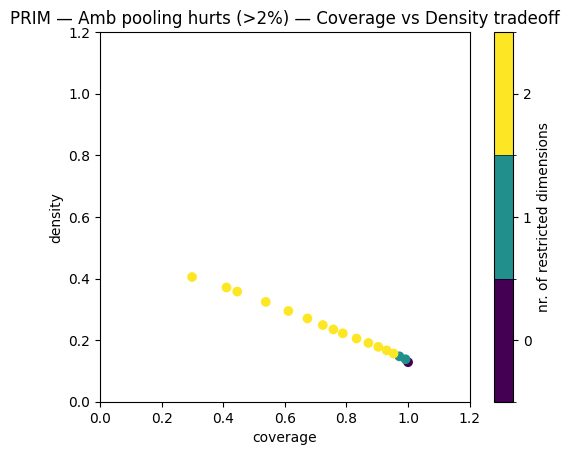

Selected step 4: coverage=0.930, density=0.167, mass=0.716
coverage        0.930300
density         0.166749
id              4.000000
k           12106.000000
mass            0.715976
mean            0.166749
n           72600.000000
res_dim         2.000000
Name: 4, dtype: float64

                    box 4                                  
                      min   max      qp value      qp value
ccp_r1_inter_bn_min  17.5  70.0  1.091211e-47           NaN
ccp_r1_same_bn_min   12.5  67.5  1.066587e-20  7.689863e-16


Box limits (where amb pooling hurts):
  bcas_rate: 0.02 — 0.07
  ccp_r1_same_bn_min: 12.5 — 67.5
  ccp_r1_inter_bn_min: 17.5 — 70.0

→ RECOMMENDATION: Ambulance pooling is safe (≤10% harm) OUTSIDE this box.
  i.e., when bcas < 0.02 OR own R1 < 12 min


In [56]:
# Select box index 4 and inspect
box.show_tradeoff()
plt.title("PRIM — Amb pooling hurts (>2%) — Coverage vs Density tradeoff")
plt.show()

best_idx = 4
box.select(best_idx)
sel = traj.iloc[best_idx]
print(f"Selected step {best_idx}: coverage={sel['coverage']:.3f}, density={sel['density']:.3f}, mass={sel['mass']:.3f}")

box.inspect(best_idx)

limits = box.box_lims[best_idx]
print(f"\nBox limits (where amb pooling hurts):")
for col in ["bcas_rate", "ccp_r1_same_bn_min", "ccp_r1_inter_bn_min"]:
    lo, hi = limits.iloc[0][col], limits.iloc[1][col]
    print(f"  {col}: {lo} — {hi}")

print(f"\n→ RECOMMENDATION: Ambulance pooling is safe (≤10% harm) OUTSIDE this box.")
print(f"  i.e., when bcas < {limits.iloc[0]['bcas_rate']:.2f} OR own R1 < {limits.iloc[0]['ccp_r1_same_bn_min']:.0f} min")

## PRIM — Where does full pooling (both) hurt?

Same approach: paired comparison of both pooling vs stovepipe across the full grid.
Target: seeds where both pooling worsens T1 mortality by more than 2%.

In [57]:
# PRIM — both pooling hurts vs stovepipe
MATCH_COLS = ["seed", "bcas_rate", "ccp_r1_same_bn_min", "ccp_r1_inter_bn_min"]

both_full = df[(df["facility_eligibility"] == 1) & (df["ambulance_eligibility"] == 1)].sort_values(MATCH_COLS).reset_index(drop=True)

assert (stove_full[MATCH_COLS].values == both_full[MATCH_COLS].values).all(), "Seed mismatch"
print(f"Paired runs: {len(both_full)}")

delta_both = both_full["death_rate_T1_BCAS"].values - stove_full["death_rate_T1_BCAS"].values
hurts_both = delta_both > 0.02

print(f"Both hurts (>2%): {hurts_both.sum()} / {len(hurts_both)} ({hurts_both.mean():.1%})")

x_both = stove_full[["bcas_rate", "ccp_r1_same_bn_min", "ccp_r1_inter_bn_min"]].astype(float).copy()

p_both = prim.Prim(x_both, hurts_both, threshold=0.2, peel_alpha=0.05)
box_both = p_both.find_box()

traj_both = box_both.peeling_trajectory
print(f"\nPeeling trajectory ({len(traj_both)} steps):")
print(traj_both[["coverage", "density", "mass", "res_dim"]].to_string(float_format="%.3f"))

Paired runs: 101400
Both hurts (>2%): 8646 / 101400 (8.5%)

Peeling trajectory (17 steps):
    coverage  density  mass  res_dim
0      1.000    0.085 1.000        0
1      0.999    0.092 0.923        1
2      0.994    0.099 0.852        2
3      0.985    0.108 0.781        2
4      0.963    0.115 0.716        2
5      0.931    0.122 0.651        2
6      0.899    0.130 0.592        2
7      0.858    0.137 0.533        2
8      0.810    0.146 0.473        2
9      0.754    0.155 0.414        2
10     0.695    0.167 0.355        2
11     0.630    0.181 0.296        2
12     0.557    0.201 0.237        2
13     0.526    0.210 0.213        2
14     0.441    0.235 0.160        2
15     0.325    0.261 0.107        2
16     0.296    0.267 0.095        2


In [58]:
# Exceedance curves — amb vs stove AND both vs stove, per bcas
from ipywidgets import interact, Dropdown

bcas_vals = sorted(df["bcas_rate"].unique())

def plot_exceedance_both(bcas):
    MATCH_COLS = ["seed", "ccp_r1_same_bn_min", "ccp_r1_inter_bn_min"]
    s = stove_full[stove_full["bcas_rate"] == bcas].sort_values(MATCH_COLS).reset_index(drop=True)
    a = amb_full[amb_full["bcas_rate"] == bcas].sort_values(MATCH_COLS).reset_index(drop=True)
    b = both_full[both_full["bcas_rate"] == bcas].sort_values(MATCH_COLS).reset_index(drop=True)

    delta_amb  = a["death_rate_T1_BCAS"].values - s["death_rate_T1_BCAS"].values
    delta_both = b["death_rate_T1_BCAS"].values - s["death_rate_T1_BCAS"].values

    thresholds = np.linspace(
        min(delta_amb.min(), delta_both.min()),
        max(delta_amb.max(), delta_both.max()), 500)

    exc_amb  = [(delta_amb >= t).mean() for t in thresholds]
    exc_both = [(delta_both >= t).mean() for t in thresholds]

    fig, ax = plt.subplots(figsize=(14, 7))
    ax.plot(thresholds, exc_amb, linewidth=2, label="Amb vs Stove", color="tab:red")
    ax.plot(thresholds, exc_both, linewidth=2, label="Both vs Stove", color="tab:purple")
    ax.axvline(0, color="gray", linestyle="--", alpha=0.7, label="δ = 0")

    ax.set_xlabel("Δ mortality threshold (policy − stove)", fontsize=13)
    ax.set_ylabel("Fraction of scenarios ≥ threshold", fontsize=13)
    ax.set_title(f"Exceedance Curve — Pooling vs Stovepipe (bcas={bcas})", fontsize=14)
    ax.legend(fontsize=12)
    ax.grid(True, alpha=0.3)

    pct_amb_hurts  = (delta_amb > 0).mean()
    pct_both_hurts = (delta_both > 0).mean()
    ax.annotate(f"Amb hurts: {pct_amb_hurts:.1%}", xy=(0.01, 1 - pct_amb_hurts),
                fontsize=10, color="tab:red")
    ax.annotate(f"Both hurts: {pct_both_hurts:.1%}", xy=(0.01, 1 - pct_both_hurts - 0.05),
                fontsize=10, color="tab:purple")

    plt.tight_layout()
    plt.show()

    print(f"bcas={bcas}: {len(delta_amb)} scenario pairs")
    print(f"  Amb  — hurts: {(delta_amb>0).mean():.1%}, helps: {(delta_amb<0).mean():.1%}, median δ: {np.median(delta_amb):+.4f}")
    print(f"  Both — hurts: {(delta_both>0).mean():.1%}, helps: {(delta_both<0).mean():.1%}, median δ: {np.median(delta_both):+.4f}")

interact(plot_exceedance_both,
         bcas=Dropdown(options=bcas_vals, value=0.07, description="BCAS rate"))

interactive(children=(Dropdown(description='BCAS rate', index=5, options=(np.float64(0.02), np.float64(0.03), …

<function __main__.plot_exceedance_both(bcas)>

In [59]:
# Diagnose the δ=0 mass: ceiling (both=100% mortality) vs dispatcher didn't use pooling?
BCAS = 0.07
MATCH_COLS = ["seed", "ccp_r1_same_bn_min", "ccp_r1_inter_bn_min"]

s = stove_full[stove_full["bcas_rate"] == BCAS].sort_values(MATCH_COLS).reset_index(drop=True)
a = amb_full[amb_full["bcas_rate"] == BCAS].sort_values(MATCH_COLS).reset_index(drop=True)
b = both_full[both_full["bcas_rate"] == BCAS].sort_values(MATCH_COLS).reset_index(drop=True)

for label, policy_df in [("Amb vs Stove", a), ("Both vs Stove", b)]:
    delta = policy_df["death_rate_T1_BCAS"].values - s["death_rate_T1_BCAS"].values
    zero_mask = np.abs(delta) < 1e-9

    n_zero = zero_mask.sum()
    mort_stove_zero = s.loc[zero_mask, "death_rate_T1_BCAS"].values
    mort_policy_zero = policy_df.loc[zero_mask, "death_rate_T1_BCAS"].values
    cross_bn_zero = policy_df.loc[zero_mask, "frac_transport_cross_bn"].values

    ceiling = (mort_policy_zero >= 1.0 - 1e-9)
    no_crossbn = (cross_bn_zero < 1e-9) & ~ceiling
    other = ~ceiling & ~no_crossbn

    print(f"{'='*60}")
    print(f"{label} — δ=0 scenarios: {n_zero} / {len(delta)} ({n_zero/len(delta):.1%})")
    print(f"  Ceiling (mortality=100%):          {ceiling.sum():5d} ({ceiling.mean():.1%})")
    print(f"  No cross-bn dispatch (mort<100%):  {no_crossbn.sum():5d} ({no_crossbn.mean():.1%})")
    print(f"  Other (used cross-bn, same mort):  {other.sum():5d} ({other.mean():.1%})")
    print()

    if other.sum() > 0:
        print(f"  'Other' mortality range: {mort_policy_zero[other].min():.3f} — {mort_policy_zero[other].max():.3f}")
        print(f"  'Other' cross-bn frac range: {cross_bn_zero[other].min():.3f} — {cross_bn_zero[other].max():.3f}")
    print()

Amb vs Stove — δ=0 scenarios: 4898 / 16900 (29.0%)
  Ceiling (mortality=100%):           2554 (52.1%)
  No cross-bn dispatch (mort<100%):      0 (0.0%)
  Other (used cross-bn, same mort):   2344 (47.9%)

  'Other' mortality range: 0.789 — 0.967
  'Other' cross-bn frac range: 0.370 — 0.621

Both vs Stove — δ=0 scenarios: 4155 / 16900 (24.6%)
  Ceiling (mortality=100%):           2077 (50.0%)
  No cross-bn dispatch (mort<100%):      0 (0.0%)
  Other (used cross-bn, same mort):   2078 (50.0%)

  'Other' mortality range: 0.789 — 0.967
  'Other' cross-bn frac range: 0.345 — 0.667


In [60]:
# Verify discretization: how many T1 patients and distinct mortality values?
BCAS = 0.07
s = stove_full[stove_full["bcas_rate"] == BCAS]

n_patients = s["n_patients_T1_BCAS"].values
print(f"T1 patient count: min={n_patients.min()}, max={n_patients.max()}, "
      f"median={np.median(n_patients):.0f}, mean={n_patients.mean():.1f}")
print(f"Distinct patient counts: {sorted(np.unique(n_patients))}")

mort_vals = sorted(s["death_rate_T1_BCAS"].unique())
print(f"\nDistinct mortality values: {len(mort_vals)}")
print(f"Smallest nonzero step: {np.min(np.diff(mort_vals)):.6f}")
print(f"Typical step size for 16 patients: {1/16:.6f}")
print(f"First 20 values: {mort_vals[:20]}")

T1 patient count: min=11, max=30, median=19, mean=19.5
Distinct patient counts: [np.int64(11), np.int64(12), np.int64(13), np.int64(14), np.int64(15), np.int64(16), np.int64(17), np.int64(18), np.int64(19), np.int64(20), np.int64(21), np.int64(22), np.int64(23), np.int64(24), np.int64(25), np.int64(26), np.int64(27), np.int64(28), np.int64(29), np.int64(30)]

Distinct mortality values: 39
Smallest nonzero step: 0.001323
Typical step size for 16 patients: 0.062500
First 20 values: [np.float64(0.7894736842105263), np.float64(0.8), np.float64(0.8235294117647058), np.float64(0.8461538461538461), np.float64(0.8571428571428571), np.float64(0.8636363636363636), np.float64(0.8666666666666667), np.float64(0.8695652173913043), np.float64(0.875), np.float64(0.88), np.float64(0.8823529411764706), np.float64(0.8888888888888888), np.float64(0.8947368421052632), np.float64(0.9), np.float64(0.9047619047619048), np.float64(0.9090909090909092), np.float64(0.9130434782608696), np.float64(0.91666666666666

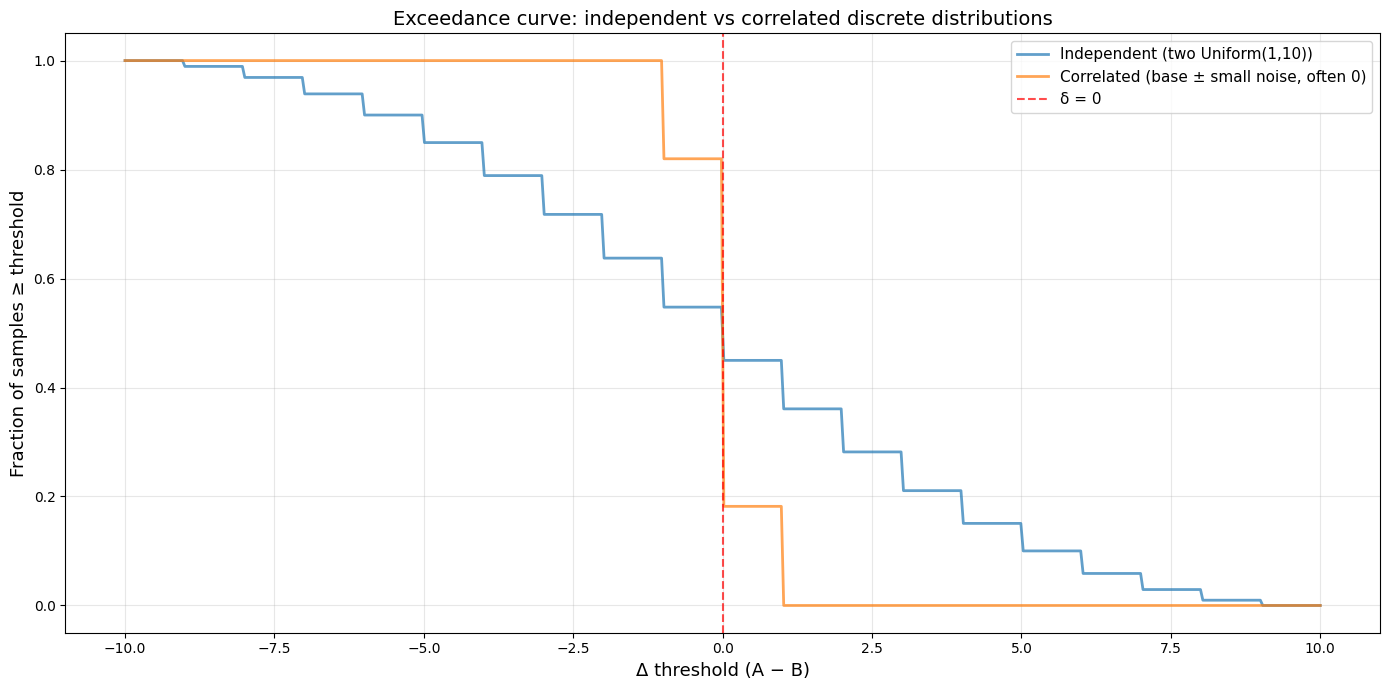

Independent — P(δ=0): 0.098
Correlated  — P(δ=0): 0.638

The correlated case produces a large jump at δ=0 because
the perturbation is often zero — same mechanism as the model.


In [64]:
# Toy: exceedance curve — independent vs correlated discrete distributions
rng = np.random.default_rng(42)
n = 100_000

# Case 1: independent draws
a1 = rng.integers(1, 11, size=n)
b1 = rng.integers(1, 11, size=n)
delta_indep = a1 - b1

# Case 2: correlated — same base, small perturbation that's often 0
base = rng.integers(1, 11, size=n)
p_zero = 0.3  # 30% chance pooling has no effect
noise = rng.choice([-1, 0, 0, 0, 1], size=n)  # ~60% zero, ~20% ±1
perturbed = np.clip(base + noise, 1, 10)
delta_corr = base - perturbed

thresholds = np.linspace(-10, 10, 500)
exc_indep = [(delta_indep >= t).mean() for t in thresholds]
exc_corr  = [(delta_corr >= t).mean() for t in thresholds]

fig, ax = plt.subplots(figsize=(14, 7))
ax.plot(thresholds, exc_indep, linewidth=2, label="Independent (two Uniform(1,10))", alpha=0.7)
ax.plot(thresholds, exc_corr, linewidth=2, label="Correlated (base ± small noise, often 0)", alpha=0.7)
ax.axvline(0, color="red", linestyle="--", alpha=0.7, label="δ = 0")

ax.set_xlabel("Δ threshold (A − B)", fontsize=13)
ax.set_ylabel("Fraction of samples ≥ threshold", fontsize=13)
ax.set_title("Exceedance curve: independent vs correlated discrete distributions", fontsize=14)
ax.legend(fontsize=11)
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

print(f"Independent — P(δ=0): {(delta_indep == 0).mean():.3f}")
print(f"Correlated  — P(δ=0): {(delta_corr == 0).mean():.3f}")
print(f"\nThe correlated case produces a large jump at δ=0 because")
print(f"the perturbation is often zero — same mechanism as the model.")

## PRIM — Where does ambulance pooling have zero effect?

Find parameter regions where amb pooling produces exactly the same mortality as stovepipe (δ=0).

In [65]:
# PRIM — amb pooling has zero effect (δ=0)
delta_amb_full = amb_full["death_rate_T1_BCAS"].values - stove_full["death_rate_T1_BCAS"].values
zero_effect = np.abs(delta_amb_full) < 1e-9

print(f"δ=0 scenarios: {zero_effect.sum()} / {len(zero_effect)} ({zero_effect.mean():.1%})")

x_zero = stove_full[["bcas_rate", "ccp_r1_same_bn_min", "ccp_r1_inter_bn_min"]].astype(float).copy()

p_zero = prim.Prim(x_zero, zero_effect, threshold=0.2, peel_alpha=0.05)
box_zero = p_zero.find_box()

traj_zero = box_zero.peeling_trajectory
print(f"\nPeeling trajectory ({len(traj_zero)} steps):")
print(traj_zero[["coverage", "density", "mass", "res_dim"]].to_string(float_format="%.3f"))

δ=0 scenarios: 30648 / 101400 (30.2%)

Peeling trajectory (21 steps):
    coverage  density  mass  res_dim
0      1.000    0.302 1.000        0
1      0.987    0.323 0.923        1
2      0.957    0.342 0.846        1
3      0.921    0.356 0.781        2
4      0.880    0.372 0.716        2
5      0.836    0.388 0.651        2
6      0.788    0.407 0.586        2
7      0.736    0.427 0.521        2
8      0.679    0.450 0.456        2
9      0.614    0.475 0.391        2
10     0.539    0.501 0.325        2
11     0.453    0.526 0.260        2
12     0.419    0.535 0.237        2
13     0.327    0.557 0.178        2
14     0.299    0.566 0.160        2
15     0.272    0.578 0.142        2
16     0.243    0.592 0.124        2
17     0.215    0.611 0.107        2
18     0.186    0.635 0.089        2
19     0.155    0.661 0.071        2
20     0.121    0.688 0.053        2


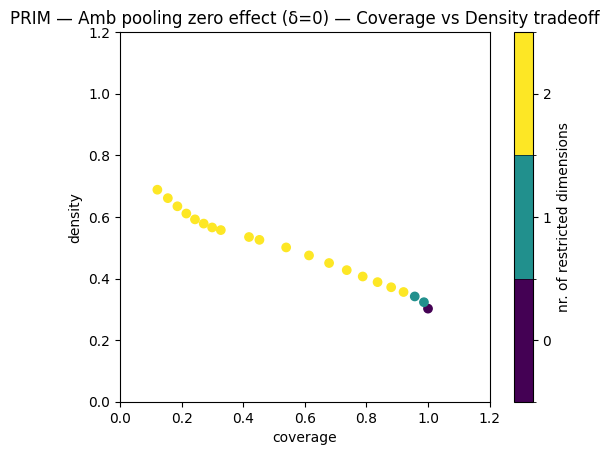

Selected step 18: coverage=0.186, density=0.635, mass=0.089
coverage       0.186342
density        0.634556
id            18.000000
k           5711.000000
mass           0.088757
mean           0.634556
n           9000.000000
res_dim        2.000000
Name: 18, dtype: float64

                    box 18                              
                       min   max       qp value qp value
ccp_r1_inter_bn_min   57.5  70.0   0.000000e+00      NaN
ccp_r1_same_bn_min    47.5  70.0  4.208007e-169      NaN


Box limits (where amb pooling has zero effect):
  bcas_rate: 0.02 — 0.07
  ccp_r1_same_bn_min: 47.5 — 70.0
  ccp_r1_inter_bn_min: 57.5 — 70.0


In [68]:
# Select box and inspect — zero effect
box_zero.show_tradeoff()
plt.title("PRIM — Amb pooling zero effect (δ=0) — Coverage vs Density tradeoff")
plt.show()

best_idx_zero = 18  # adjust after seeing trajectory
box_zero.select(best_idx_zero)
sel_zero = traj_zero.iloc[best_idx_zero]
print(f"Selected step {best_idx_zero}: coverage={sel_zero['coverage']:.3f}, density={sel_zero['density']:.3f}, mass={sel_zero['mass']:.3f}")

box_zero.inspect(best_idx_zero)

limits_zero = box_zero.box_lims[best_idx_zero]
print(f"\nBox limits (where amb pooling has zero effect):")
for col in ["bcas_rate", "ccp_r1_same_bn_min", "ccp_r1_inter_bn_min"]:
    lo, hi = limits_zero.iloc[0][col], limits_zero.iloc[1][col]
    print(f"  {col}: {lo} — {hi}")

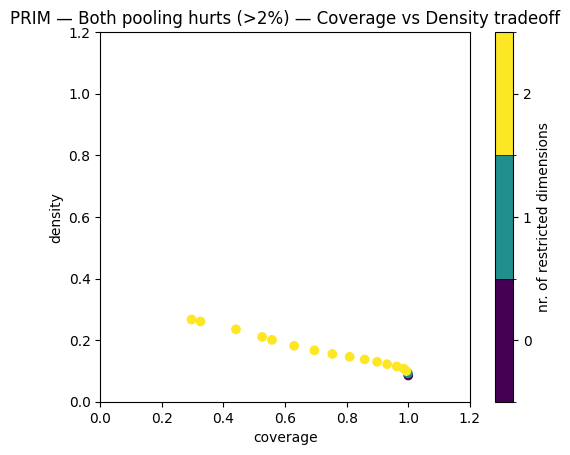

Selected step 3: coverage=0.985, density=0.108, mass=0.781
coverage        0.985427
density         0.107576
id              3.000000
k            8520.000000
mass            0.781065
mean            0.107576
n           79200.000000
res_dim         2.000000
Name: 3, dtype: float64

                    box 3                             
                      min   max      qp value qp value
ccp_r1_inter_bn_min  17.5  70.0  1.622489e-50      NaN
ccp_r1_same_bn_min   12.5  70.0  2.963418e-13      NaN


Box limits (where both pooling hurts):
  bcas_rate: 0.02 — 0.07
  ccp_r1_same_bn_min: 12.5 — 70.0
  ccp_r1_inter_bn_min: 17.5 — 70.0

→ RECOMMENDATION: Full pooling is safe (≤10% harm) OUTSIDE this box.


In [61]:
# Select box and inspect — both pooling
box_both.show_tradeoff()
plt.title("PRIM — Both pooling hurts (>2%) — Coverage vs Density tradeoff")
plt.show()

best_idx_both = 3  # adjust after seeing trajectory
box_both.select(best_idx_both)
sel_both = traj_both.iloc[best_idx_both]
print(f"Selected step {best_idx_both}: coverage={sel_both['coverage']:.3f}, density={sel_both['density']:.3f}, mass={sel_both['mass']:.3f}")

box_both.inspect(best_idx_both)

limits_both = box_both.box_lims[best_idx_both]
print(f"\nBox limits (where both pooling hurts):")
for col in ["bcas_rate", "ccp_r1_same_bn_min", "ccp_r1_inter_bn_min"]:
    lo, hi = limits_both.iloc[0][col], limits_both.iloc[1][col]
    print(f"  {col}: {lo} — {hi}")

print(f"\n→ RECOMMENDATION: Full pooling is safe (≤10% harm) OUTSIDE this box.")